In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ruta = "../data/Superstore_Orders.csv"
df = pd.read_csv(ruta)

In [15]:
#Limpieza: Convertir texto a números 
df['Sales'] = df['Sales'].str.replace(',', '.').astype(float)
df['Profit'] = df['Profit'].str.replace(',', '.').astype(float)
df['Discount'] = df['Discount'].str.replace(',', '.').astype(float)

#Verificar 
print("Primeras 5 filas limpias:")
print(df[['Sales', 'Profit', 'Discount']].head())

Primeras 5 filas limpias:
      Sales    Profit  Discount
0  261.9600   41.9136      0.00
1  731.9400  219.5820      0.00
2   14.6200    6.8714      0.00
3  957.5775 -383.0310      0.45
4   22.3680    2.5164      0.20


In [16]:
#Exploración de los datos
print("Primeras 5 filas del dataset completo:")
display(df.head())

print("\n--- Información de las columnas ---")
df.info()

print("\n--- Resumen estadístico (datos numéricos) ---")
display(df.describe())

Primeras 5 filas del dataset completo:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,8/11/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,8/11/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,12/6/2016,16/6/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,11/10/2015,18/10/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,11/10/2015,18/10/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164



--- Información de las columnas ---
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-nu

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


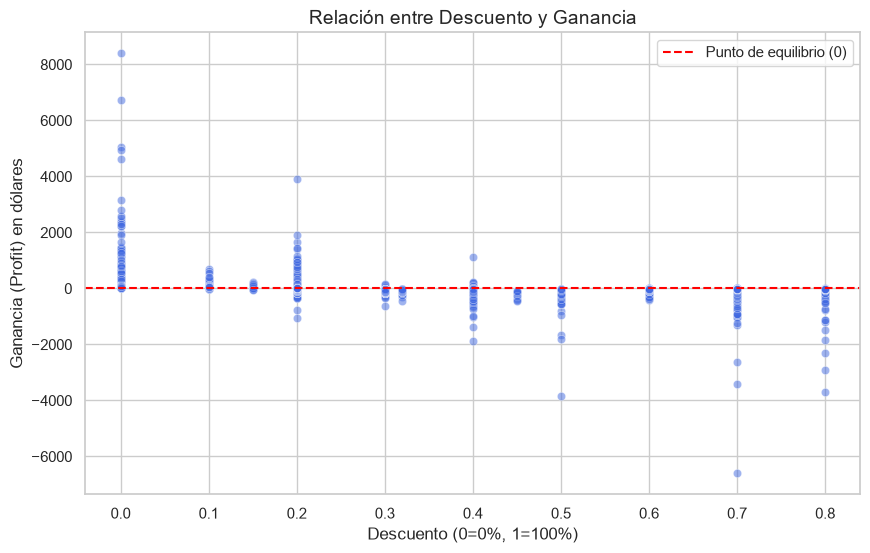

In [ ]:
# grafico
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Discount', y='Profit',  alpha=0.5, color='royalblue')

plt.title('Relación entre Descuento y Ganancia', fontsize=14)
plt.xlabel('Descuento (0=0%, 1=100%)', fontsize=12)
plt.ylabel('Ganancia (Profit) en dólares', fontsize=12)

#linea de referencia en y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Punto de equilibrio (0)')
plt.legend()

plt.savefig('../outputs/grafico_descuentos.png', bbox_inches='tight', dpi=300)
plt.show()

C:\Users\Johany\AppData\Local\Temp\ipykernel_24092\1857747071.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Category', y='Profit', errorbar=None, palette='Set2')


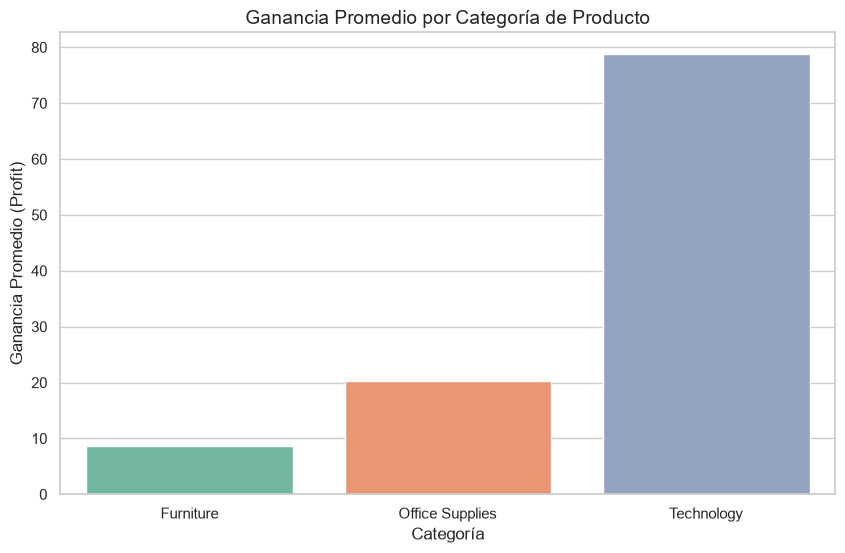


--- Suma total de Profit por Categoría ---
Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64


In [ ]:
# Gráfico de barras: Profit total por Categoría
plt.figure(figsize=(10, 6))

# Usar sns.barplot
sns.barplot(data=df, x='Category', y='Profit', errorbar=None, palette='Set2')

# Títulos
plt.title('Ganancia Promedio por Categoría de Producto', fontsize=14)
plt.xlabel('Categoría', fontsize=12)
plt.ylabel('Ganancia Promedio (Profit)', fontsize=12)

plt.savefig('../outputs/grafico_categorias.png', bbox_inches='tight', dpi=300)
plt.show()

# Ver numeros de perdidas
print("\n--- Suma total de Profit por Categoría ---")
print(df.groupby('Category')['Profit'].sum().sort_values())

C:\Users\Johany\AppData\Local\Temp\ipykernel_24092\154538665.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=profit_por_subcategoria.values, y=profit_por_subcategoria.index, palette='RdYlGn')


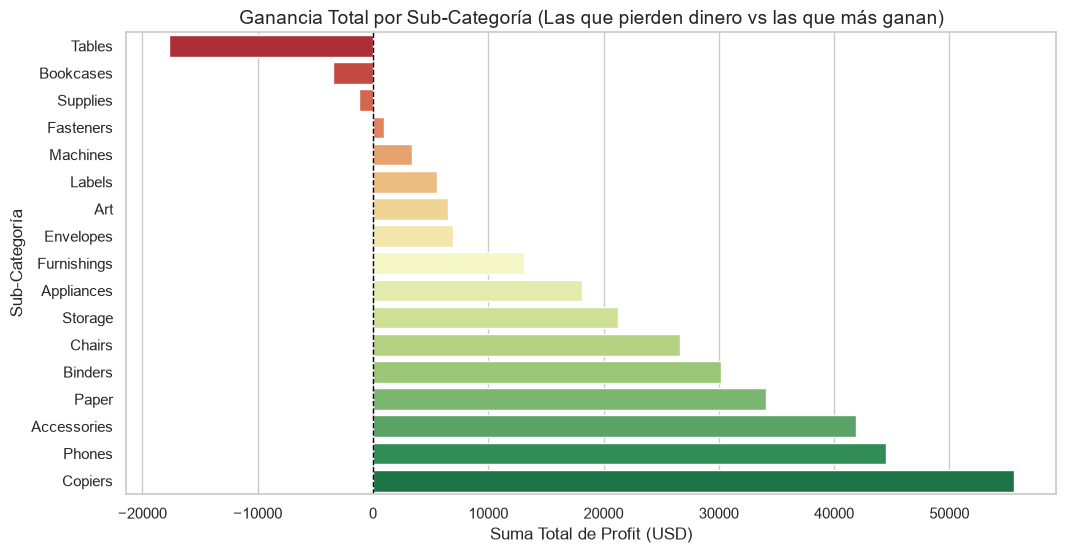

In [ ]:
#Agrupar por Sub-Categoría y sumar el Profit
profit_por_subcategoria = df.groupby('Sub-Category')['Profit'].sum().sort_values()

# Crear el gráfico de barras
plt.figure(figsize=(12, 6))
sns.barplot(x=profit_por_subcategoria.values, y=profit_por_subcategoria.index, palette='RdYlGn')

# Títulos
plt.title('Ganancia Total por Sub-Categoría (Las que pierden dinero vs las que más ganan)', fontsize=14)
plt.xlabel('Suma Total de Profit (USD)', fontsize=12)
plt.ylabel('Sub-Categoría', fontsize=12)

# Añadir línea vertical en el cero para ver las pérdidas
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)

plt.savefig('../outputs/grafico_subcategoria.png', bbox_inches='tight', dpi=300)
plt.show()

In [20]:
# Filtrar solo las ventas de "Tables"
df_tables = df[df['Sub-Category'] == 'Tables']

# Ver el resumen estadístico de las mesas
print("--- Resumen de ventas de Mesas (Tables) ---")
display(df_tables[['Sales', 'Discount', 'Profit']].describe())

#Comparar con las Copiers (Fotocopiadoras)
df_copiers = df[df['Sub-Category'] == 'Copiers']
print("\n--- Resumen de ventas de Fotocopiadoras (Copiers) ---")
display(df_copiers[['Sales', 'Discount', 'Profit']].describe())

--- Resumen de ventas de Mesas (Tables) ---


,Sales,Discount,Profit
count,319.000000,319.000000,319.000000
mean,648.794771,0.261285,-55.565771
std,615.774655,0.169622,230.565006
min,24.368000,0.000000,-1862.312400
25%,244.006000,0.200000,-122.829300
50%,447.840000,0.300000,-31.372200
75%,872.170000,0.400000,33.851700
max,4297.644000,0.500000,629.010000



--- Resumen de ventas de Fotocopiadoras (Copiers) ---


,Sales,Discount,Profit
count,68.000000,68.000000,68.000000
mean,2198.941618,0.161765,817.909190
std,3175.665867,0.130475,1460.921156
min,299.990000,0.000000,59.998000
25%,599.987500,0.000000,164.245725
50%,1099.980000,0.200000,332.994200
75%,2399.960000,0.200000,848.736375
max,17499.950000,0.400000,8399.976000
